# OCTree on the Electricity Dataset: Reproduction and Experiments

This notebook reproduces **OCTree** (Nam et al., NeurIPS 2024) at small scale on the electricity dataset
(OpenML 44156) in the **context-agnostic** setting, then runs our own experiments and saves the final model
for deployment.

**The method in one paragraph.** XGBoost is trained on the eight anonymous columns `x1 … x8`. An LLM is then
asked to write a *rule* that creates a new column, for example `x9 = [x4 * x1]`. We add that column, retrain
XGBoost, and measure validation accuracy. We also fit a small decision tree (CART) on the new data and write
it out as text. The rule, its score and the tree are shown to the LLM, which proposes a better rule. After a
fixed number of rounds the rule with the best validation score is kept, and the process can repeat for a
second new column.

| Part | Section | What it gives the report |
|---|---|---|
| Setup | 0 – 3 | Environment, data, baseline, LLM connection |
| Understanding | 4 | One OCTree step done by hand |
| **Reproduction** | 5 – 6 | OCTree result vs the paper (Table 2) and the tree-feedback ablation (Table 6) |
| **Our experiments** | 7 | Hand-made features vs OCTree (baseline comparison); training-set size (data size) |
| Deployment | 8 | Final trained model saved for the app |

All reusable code lives in `octree_core.py`. Every function there is labelled **[REUSED]** (authors' code),
**[ADAPTED]** (authors' logic rewritten) or **[OURS]**; the README has the full table.

## 0. Setup

**On Google Colab:**
1. *Runtime → Change runtime type → T4 GPU* (XGBoost trains much faster on a GPU; a CPU also works).
2. Put `octree_electricity.zip` in a folder called `octree` in your Google Drive
   (or upload it with the file panel on the left).
3. Run the next cell and allow access to Google Drive when asked.

Everything (data, saved runs, model) is kept in `My Drive/octree/octree_electricity/`. Colab deletes its own
files when it disconnects, so keeping them in Drive is what lets a stopped run continue the next day.

**On your own computer:** open this notebook from inside the project folder; the cell does nothing.

In [1]:
import os, zipfile

USE_GOOGLE_DRIVE = True        # Colab only: keep all files in Google Drive so progress survives disconnects

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if not os.path.exists("octree_core.py"):
    if IN_COLAB and USE_GOOGLE_DRIVE:
        from google.colab import drive
        drive.mount("/content/drive")
        base = "/content/drive/MyDrive/octree"
    else:
        base = "/content" if IN_COLAB else "."
    os.makedirs(base, exist_ok=True)
    project = os.path.join(base, "octree_electricity")
    if not os.path.exists(os.path.join(project, "octree_core.py")):
        zips = [z for z in (os.path.join(base, "octree_electricity.zip"), "/content/octree_electricity.zip",
                            "octree_electricity.zip") if os.path.exists(z)]
        assert zips, "Put octree_electricity.zip in My Drive/octree/ (or upload it) and run this cell again."
        zipfile.ZipFile(zips[0]).extractall(base)
    os.chdir(project)
assert os.path.exists("octree_core.py"), "Open this notebook inside the project folder (next to octree_core.py)."
print("Working folder:", os.getcwd())

# Libraries that Colab does not include by default.
%pip install -q xgboost openai

Mounted at /content/drive
Working folder: /content/drive/MyDrive/octree/octree_electricity


In [2]:
import json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import octree_core as oc          # all the OCTree code (data, rules, prompt, loop, model)

pd.set_option("display.max_colwidth", 120)
print("XGBoost will train on:", oc.xgb_device())

XGBoost will train on: cuda


## 1. Settings

Everything you may want to change is in this one cell.

**LLM.** The authors run a Llama 2 model on their own GPU. We call an LLM through a free API instead, which
needs no GPU. Default: Google Gemini (free key from https://aistudio.google.com/apikey). Store the key as a
Colab secret named `GEMINI_API_KEY` (key icon on the left, turn on "Notebook access"), or paste it below.
Leave `LLM_MODEL` empty the first time: Section 3 prints the model names your key can use. Prefer a
**Flash-Lite** model (fast, high free daily limit, no long "thinking"), or `gemma-3-27b-it` (open weights,
closest in spirit to the paper's Llama 2). Groq (`GROQ_API_KEY`, `llama-3.1-8b-instant`) also works but its
free daily token limit allows only about 100 OCTree prompts per day.

**Size of the experiment.** Start with `PROFILE = "quick"` to check that everything works (a few minutes),
then switch to `"full"` for the real results. The full profile follows the paper: 50 proposals per feature and
three random splits. It makes about 100 LLM calls per split for each LLM run, so free daily limits may spread
it over more than one day. Progress is saved after every step, so re-running a cell continues where it stopped.
If time runs short, you may lower `n_iters` in the `"full"` profile and re-run: unfinished runs continue with the
new value (report the value you used).

In [3]:
# ----------------------------- LLM -----------------------------
LLM_PROVIDER = "gemini"    # "gemini" | "groq" | "openrouter" | "ollama" | "hf_local"
LLM_MODEL    = "gemini-3.5-flash-lite"   # model name at the provider (the one used for our results)
LLM_API_KEY  = ""          # your key, or leave "" to read it from a Colab secret / environment variable
SECONDS_BETWEEN_CALLS = 4  # pause between LLM calls; raise it if you keep hitting per-minute limits

# "hf_local"    = the authors' own Llama 2 model, run on a GPU (free Colab T4). Slower, but no limits.

# ---------------------- size of the experiment ----------------------
PROFILE = "full"           # "quick" (trial run) or "full" (real experiment)
PROFILES = {
    #         splits            proposals/feature  max new features  XGBoost trees (None = authors' tuned value)
    "quick": dict(seeds=[0],       n_iters=5,         max_features=1,   n_estimators=300),
    "full":  dict(seeds=[0, 1, 2], n_iters=50,        max_features=2,   n_estimators=None),
}
CFG = PROFILES[PROFILE]

# Ablation (Section 5.1) doubles the LLM calls. Leave it False on the first pass so the main
# results, experiments and model are ready first; then set it True and run Sections 5.1 and 6 again.
RUN_ABLATION = True

# Names under which runs are saved in runs/. Change RUN_TAG if you switch to a different LLM.
RUN_TAG        = PROFILE
RUN_OCTREE     = f"{RUN_TAG}_octree"              # full method: scores + decision trees
RUN_SCORE_ONLY = f"{RUN_TAG}_octree_score_only"   # ablation: scores only
RUN_MANUAL     = f"{RUN_TAG}_manual_features"     # experiment 7.1: hand-made features
RUN_DATA_SIZE  = f"{RUN_TAG}_data_size"           # experiment 7.2: training-set size
print(CFG)

{'seeds': [0, 1, 2], 'n_iters': 50, 'max_features': 2, 'n_estimators': None}


## 2. Data and baseline (Step 0)

The data is the output of our preprocessing notebook: three random 60/20/20 splits, every column min-max
scaled using the training part, columns named `x1 … x8`.

The baseline is XGBoost on the original eight columns. We use the **tuned hyperparameters the authors
published** for these exact splits (`ours/params.py` in their repository), so we do not repeat their
400-trial search. The paper reports a baseline test error of **8.32%**.

In [4]:
oc.prepare_data("dataset", seeds=CFG["seeds"])       # does nothing if dataset/seed*/ already exists

rows = []
for seed in CFG["seeds"]:
    s = oc.load_split(seed)
    t0 = time.time()
    tr, va, te, _ = oc.fit_and_score(s["xtrain"], s["ytrain"], s["xval"], s["yval"],
                                     s["xtest"], s["ytest"], seed, CFG["n_estimators"])
    rows.append({"seed": seed, "train rows": len(s["ytrain"]), "columns": s["xtrain"].shape[1],
                 "val accuracy %": round(va * 100, 2), "test accuracy %": round(te * 100, 2),
                 "test error %": round(100 - te * 100, 2), "fit seconds": round(time.time() - t0, 1)})
baseline = pd.DataFrame(rows)
display(baseline)
print(f"Our baseline test error: {baseline['test error %'].mean():.2f} ± {baseline['test error %'].std(ddof=0):.2f} %"
      f"   |   paper: {oc.PAPER['baseline']} %")

# Rough time budget for the LLM runs (upper bound: the second feature is skipped if the first one is not accepted).
n_llm_runs = 1 + int(RUN_ABLATION)
fits = CFG["max_features"] * (CFG["n_iters"] + 1) + 1
calls = CFG["max_features"] * CFG["n_iters"]
sec_per_split = baseline["fit seconds"].mean() * fits + calls * (SECONDS_BETWEEN_CALLS + 3)
print(f"Estimated time for Section 5: up to {sec_per_split * len(CFG['seeds']) * n_llm_runs / 3600:.1f} hours "
      f"({calls} LLM calls and {fits} XGBoost fits per split and run). It can be split over several sessions.")

,seed,train rows,columns,val accuracy %,test accuracy %,test error %,fit seconds
0,0,23084,8,91.35,91.59,8.41,8.5
1,1,23084,8,91.40,91.63,8.37,8.6
2,2,23084,8,90.83,91.27,8.73,21.9


Our baseline test error: 8.50 ± 0.16 %   |   paper: 8.32 %
Estimated time for Section 5: up to 3.4 hours (100 LLM calls and 103 XGBoost fits per split and run). It can be split over several sessions.


## 3. Connect the LLM

The LLM touches the method in exactly one place: it receives the prompt as text and returns text that
contains a rule. In the authors' code this is the function `use_api()`, which runs Llama 2 locally. Here it is
the object `llm`: calling `llm(prompt)` sends the prompt to the provider and returns the answer.

In [5]:
if LLM_PROVIDER == "hf_local":
    llm = oc.HFLocalLLM()                               # downloads the authors' Llama 2 (needs a GPU runtime)
else:
    key = LLM_API_KEY or os.environ.get(oc.PROVIDERS[LLM_PROVIDER]["key_env"], "")
    if not key:                                         # Colab: key stored under the "key" icon on the left
        try:
            from google.colab import userdata
            key = userdata.get(oc.PROVIDERS[LLM_PROVIDER]["key_env"])
        except Exception:
            pass
    llm = oc.ChatLLM(LLM_PROVIDER, LLM_MODEL or "not-set", api_key=key,
                     min_seconds_between_calls=SECONDS_BETWEEN_CALLS)
    print("Models your key can use:")
    print(llm.list_models())
    assert LLM_MODEL, "Now set LLM_MODEL in the settings cell to one of these names and run again from there."

# One small test call: the answer should contain a rule in the form  x9 = [ ... ]
answer = llm("Reply with exactly this and nothing else: x9 = [x1 * x2]", 8)
print("\nRaw answer :", repr(answer[:300]))
print("Parsed rule:", oc.extract_rule(answer, 9))

Models your key can use:
['antigravity-preview-05-2026', 'antigravity-preview-09-2026', 'antigravity-preview-latest', 'aqa', 'deep-research-max-preview-04-2026', 'deep-research-preview-04-2026', 'gemini-2.5-computer-use-preview-10-2025', 'gemini-2.5-flash', 'gemini-2.5-flash-image', 'gemini-2.5-flash-lite', 'gemini-2.5-flash-native-audio-latest', 'gemini-2.5-flash-native-audio-preview-09-2025', 'gemini-2.5-flash-native-audio-preview-12-2025', 'gemini-2.5-flash-preview-tts', 'gemini-2.5-pro', 'gemini-2.5-pro-preview-tts', 'gemini-3-flash-preview', 'gemini-3-pro-image', 'gemini-3-pro-image-preview', 'gemini-3.1-flash-image', 'gemini-3.1-flash-image-preview', 'gemini-3.1-flash-lite', 'gemini-3.1-flash-lite-image', 'gemini-3.1-flash-lite-preview', 'gemini-3.1-flash-live-preview', 'gemini-3.1-flash-tts-preview', 'gemini-3.1-pro-preview', 'gemini-3.1-pro-preview-customtools', 'gemini-3.5-flash', 'gemini-3.5-flash-lite', 'gemini-3.5-live-translate-preview', 'gemini-3.5-transcribe', 'gemini-3.

## 4. One OCTree step by hand

Before running the full loop, this section performs a single step on split 0 so each part is visible:

1. **Initial rule.** Multiply the two columns XGBoost finds most important.
2. **Evaluate it.** Compute the new column, scale it, retrain XGBoost, read the validation accuracy.
3. **Decision tree reasoning.** Fit a small CART tree on the new data and print it as if/else text.
4. **Prompt.** Put rule, tree and score into the authors' prompt.
5. **Ask the LLM** and parse the new rule from its answer.

In [6]:
s = oc.load_split(0)
Xtr, Xva, Xte = s["xtrain"], s["xval"], s["xtest"]
ytr, yva, yte = s["ytrain"], s["yval"], s["ytest"]

# 1. Initial rule: product of the two most important columns
r0 = oc.initial_rule(Xtr, ytr, Xva, yva)
print("1. Initial rule:", r0)

# 2. Evaluate: new column -> scale with training min/max -> append -> train XGBoost
ctr, cva, cte, lo, hi = oc.scale_column(oc.apply_rule(r0, Xtr), oc.apply_rule(r0, Xva), oc.apply_rule(r0, Xte))
Ntr, Nva, Nte = np.c_[Xtr, ctr], np.c_[Xva, cva], np.c_[Xte, cte]
tr, va, te, _ = oc.fit_and_score(Ntr, ytr, Nva, yva, Nte, yte, 0, CFG["n_estimators"])
print(f"2. With x9: validation accuracy {va * 100:.2f}%  (this is the score the LLM sees, as {va * 10000:.0f})")

# 3. Decision tree reasoning: CART written as text
cart = oc.fit_cart(Ntr, ytr, Nva, yva, seed=0)
tree_text = oc.tree_to_text(cart, [f"x{i}" for i in range(1, Ntr.shape[1] + 1)])
print("3. Decision tree (CART):\n" + tree_text)

# 4. The prompt
prompt = oc.build_prompt([r0], [tree_text], [va], target_idx=9, use_tree=True)
print("4. Prompt sent to the LLM:\n" + "-" * 80 + "\n" + prompt + "\n" + "-" * 80)

1. Initial rule: x9 = [x4 * x1]
2. With x9: validation accuracy 91.44%  (this is the score the LLM sees, as 9144)
3. Decision tree (CART):
if x4 > 0.07:
  if x4 > 0.08:
    if x9 > 0.00:
      y = 1.
    else:
      y = 1.
  else:
    if x3 > 0.24:
      y = 1.
    else:
      y = 0.
else:
  if x5 > 0.27:
    if x1 > 0.43:
      y = 0.
    else:
      y = 0.
  else:
    if x4 > 0.06:
      y = 0.
    else:
      y = 0.

4. Prompt sent to the LLM:
--------------------------------------------------------------------------------
I have some rules to generate x9 from x1, x2, x3, x4, x5, x6, x7, x8. We also have corresponding decision tree (CART) to predict 'y' from x1, x2, x3, x4, x5, x6, x7, x8, x9. The rules are arragned in ascending order based on their scores evaluated with XGBoost classifier, where higher scores indicates better quality.

Rule to generate x9:
x9 = [x4 * x1]
Decision tree (CART):
if x4 > 0.07:
  if x4 > 0.08:
    if x9 > 0.00:
      y = 1.
    else:
      y = 1.
  else

In [7]:
# 5. Ask the LLM and read the rule out of its answer
answer = llm(prompt, 8)
rule = oc.extract_rule(answer, 9)
print("LLM answer :", answer.strip()[:400])
print("Parsed rule:", rule)
if rule:
    try:
        col = oc.apply_rule(rule, Xtr)
        print("The rule runs: first values of the new column =", np.round(col[:5], 4))
    except oc.InvalidRule as e:
        print("This rule would be rejected and the LLM asked again:", e)

LLM answer : [np.maximum(x2 * x3, x6 * x8)]
Parsed rule: x9 = [np.maximum(x2 * x3, x6 * x8)]
The rule runs: first values of the new column = [0.0035 0.0532 0.227  0.1702 0.1596]


## 5. Reproduction: run OCTree

`oc.run_octree` repeats the step above. For each new feature it starts from the initial rule, asks for
`n_iters` new rules, and keeps the one with the best **validation** score, but only if it beats the model we
had before. Then it tries a second feature (`x10`) on top of the first, and stops when validation no longer
improves, as in Section 3.2 of the paper.

Test accuracy is recorded for reporting only. It is never shown to the LLM and never used to choose a rule.

If the LLM hits a rate or daily limit, the cell stops with a message. **Run the cell again later and it
continues from the saved state.**

In [8]:
for seed in CFG["seeds"]:
    oc.run_octree(seed, llm, RUN_OCTREE, n_iters=CFG["n_iters"], max_features=CFG["max_features"],
                  use_tree=True, n_estimators=CFG["n_estimators"])

[full_octree | seed 0] Step 0 (original columns) | Val: 91.35 | Test: 91.59
[full_octree | seed 0] Final test error 7.76% (baseline 8.41%) with 2 generated feature(s)
[full_octree | seed 1] Step 0 (original columns) | Val: 91.40 | Test: 91.63
[full_octree | seed 1] Final test error 7.52% (baseline 8.37%) with 2 generated feature(s)
[full_octree | seed 2] Step 0 (original columns) | Val: 90.83 | Test: 91.27
[full_octree | seed 2] Final test error 7.71% (baseline 8.73%) with 2 generated feature(s)


### 5.1 Reproduction of the ablation: is the decision tree needed?

Table 6 of the paper removes the decision tree from the prompt (the LLM sees only rules and scores) and
reports 6.89% error on electricity instead of 6.65%. This run repeats that ablation with our LLM:
`use_tree=False` builds the same prompt without any mention of decision trees.

In [9]:
if RUN_ABLATION:
    for seed in CFG["seeds"]:
        oc.run_octree(seed, llm, RUN_SCORE_ONLY, n_iters=CFG["n_iters"], max_features=CFG["max_features"],
                      use_tree=False, n_estimators=CFG["n_estimators"])
else:
    print("Skipped (RUN_ABLATION = False). Set it to True in Section 1 when the other sections are done.")

[full_octree_score_only | seed 0] Step 0 (original columns) | Val: 91.35 | Test: 91.59
[full_octree_score_only | seed 0] Final test error 7.68% (baseline 8.41%) with 2 generated feature(s)
[full_octree_score_only | seed 1] Step 0 (original columns) | Val: 91.40 | Test: 91.63
[full_octree_score_only | seed 1] Final test error 7.37% (baseline 8.37%) with 2 generated feature(s)
[full_octree_score_only | seed 2] Step 0 (original columns) | Val: 90.83 | Test: 91.27
[full_octree_score_only | seed 2] Final test error 8.07% (baseline 8.73%) with 2 generated feature(s)


## 6. Reproduction results

The table compares our test errors with the paper's. Values are mean ± standard deviation over the splits.
*Relative reduction* is the drop in error compared with the baseline, the number the paper puts in brackets.

In [10]:
ours = oc.summarise([RUN_OCTREE, RUN_SCORE_ONLY], seeds=CFG["seeds"])
paper = pd.DataFrame([
    {"run": "paper: OCTree", "seeds": 3, "baseline error %": "8.32 ± 0.0", "test error %": "6.65 ± 0.1", "relative reduction %": 20.1},
    {"run": "paper: OCTree without decision tree", "seeds": 3, "baseline error %": "8.32 ± 0.0", "test error %": "6.89 ± 0.6", "relative reduction %": 17.2},
])
display(pd.concat([ours.astype(object), paper.astype(object)], ignore_index=True).fillna(""))

/tmp/ipykernel_332/2059926157.py:6: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  display(pd.concat([ours.astype(object), paper.astype(object)], ignore_index=True).fillna(""))


,run,seeds,baseline error %,test error %,relative reduction %,features kept (per seed),proposals,unusable answers
0,full_octree,3,8.50 ± 0.16,7.66 ± 0.10,9.9,"[2, 2, 2]",341,41
1,full_octree_score_only,3,8.50 ± 0.16,7.71 ± 0.29,9.4,"[2, 2, 2]",327,27
2,paper: OCTree,3,8.32 ± 0.0,6.65 ± 0.1,20.1,,,
3,paper: OCTree without decision tree,3,8.32 ± 0.0,6.89 ± 0.6,17.2,,,


In [11]:
# The rules that were kept, with the real column names (for us only; the LLM never saw these names).
names = {f"x{i + 1}": c for i, c in enumerate(oc.RAW_COLUMNS)}
for seed in CFG["seeds"]:
    run = oc.load_run(RUN_OCTREE, seed)
    if not run or not run.get("final"):
        continue
    print(f"Split {seed}: test error {run['final']['baseline_error']:.2f}% -> {run['final']['test_error']:.2f}%")
    for rule in run["final"]["rules"]:
        readable = rule
        for k in sorted(names, key=len, reverse=True):
            readable = readable.replace(k, names[k])
        print("   ", rule, "   meaning:", readable.split("=", 1)[1].strip())

Split 0: test error 8.41% -> 7.76%
    x9 = [np.where(x4 > 0.07, x1 * x3 * x4 + np.sin(x6 * x8) * (1 - x2), np.cos(x5 * x7) + x1 * x2 * (1 - x4))]    meaning: [np.where(nswprice > 0.07, date * period * nswprice + np.sin(vicprice * transfer) * (1 - day), np.cos(nswdemand * vicdemand) + date * day * (1 - nswprice))]
    x10 = [np.where(x4 > 0.08, x3 * x9 * (np.abs(x1 - x5) + np.sin(x2 * x6) * np.exp(-x4)), x1 * x4 * np.cos(x3) + x7 * x8 * np.sin(x9) + np.sin(x1 * x2) * np.cos(x4))]    meaning: [np.where(nswprice > 0.08, period * x9 * (np.abs(date - nswdemand) + np.sin(day * vicprice) * np.exp(-nswprice)), date * nswprice * np.cos(period) + vicdemand * transfer * np.sin(x9) + np.sin(date * day) * np.cos(nswprice))]
Split 1: test error 8.37% -> 7.52%
    x9 = [x4 * x1 * (x3 + x5 + 1.0) * (np.abs(x1 - x5) + 1.0) * np.maximum(x2, x6)]    meaning: [nswprice * date * (period + nswdemand + 1.0) * (np.abs(date - nswdemand) + 1.0) * np.maximum(day, vicprice)]
    x10 = [np.power(x4, 3) * np.sin(x

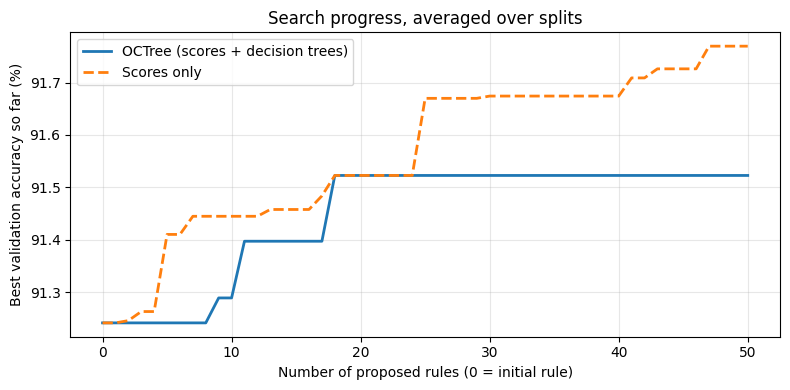

In [12]:
# How the search progressed: best validation accuracy so far, for the first generated feature.
def plot_progress(run_names, labels, title):
    fig, ax = plt.subplots(figsize=(8, 4))
    for name, label, style in zip(run_names, labels, ["-", "--", ":"]):
        curves = []
        for seed in CFG["seeds"]:
            run = oc.load_run(name, seed)
            if run and run["rounds"]:
                curves.append(np.array(oc.best_so_far(run)[0]["best_val"]) * 100)
        if curves:
            n = min(len(c) for c in curves)
            ax.plot(range(n), np.mean([c[:n] for c in curves], axis=0), style, label=label, linewidth=2)
    ax.set_xlabel("Number of proposed rules (0 = initial rule)")
    ax.set_ylabel("Best validation accuracy so far (%)")
    ax.set_title(title)
    ax.grid(alpha=0.3)
    ax.legend()
    plt.tight_layout()
    plt.show()

plot_progress([RUN_OCTREE, RUN_SCORE_ONLY], ["OCTree (scores + decision trees)", "Scores only"],
              "Search progress, averaged over splits")

## 7. Our own experiments

The project brief asks for at least one experiment beyond the paper. We run two, both on the same splits and
with the same XGBoost settings as the reproduction:

| | Brief category | Question |
|---|---|---|
| **7.1** | C. Baseline comparison | Does an LLM that cannot see what the columns mean beat features designed by a person who can? |
| **7.2** | E. Data size experiment | Do generated features help more when there is less training data? |

Neither experiment needs extra LLM calls: 7.1 uses only hand-made features, and 7.2 reuses the features
already found in Section 5.

### 7.1 Hand-made features vs OCTree (Baseline comparison)

**Question.** OCTree works without knowing what `x1 … x8` mean. A person *does* know: `x4` is the NSW price,
`x6` the Victoria price, `x3` the time of day, and so on. Can simple features built from that knowledge do as
well as the LLM's features?

**Design, kept as fair as possible:**

* **Same kind of feature.** Every hand-made feature uses only the values in the same row, exactly like
  OCTree's rules. We do *not* use features that look at earlier half-hours (such as a moving average of the
  price), because OCTree cannot build those, and because some rows were removed when the classes were balanced,
  so the neighbouring half-hour is often missing.
* **Same selection rule.** Each candidate is tried as `x9`; the best one on **validation** data is kept only if
  it beats the original columns. The rest are then tried as `x10` on top of it, up to the same maximum number
  of features as OCTree. Test data is never used to choose.
* **Same model.** XGBoost with the authors' tuned settings.

We also report all seven features added at once, without any selection.

In [13]:
display(pd.DataFrame(oc.MANUAL_FEATURES).rename(columns={"name": "feature", "expr": "rule (x9 = ...)", "why": "reason"}))

,feature,rule (x9 = ...),reason
0,price_gap,x4 - x6,"NSW price minus Victoria price: when NSW is dearer than its neighbour, prices tend to move"
1,demand_gap,x5 - x7,NSW demand minus Victoria demand: relative pressure on the two markets
2,price_x_demand,x4 * x5,NSW price times NSW demand: high price under high demand signals a tight market
3,period_sin,np.sin(2 * np.pi * x3),"time of day as a circle (23:30 sits next to 00:00), first coordinate"
4,period_cos,np.cos(2 * np.pi * x3),"time of day as a circle, second coordinate"
5,peak_hours,1.0 if 14 / 47 <= x3 < 44 / 47 else 0.0,"1 during roughly 07:00-22:00 (half-hour slots 14-43), when demand and prices peak"
6,transfer_x_price_gap,x8 * (x4 - x6),interstate transfer weighted by the price gap: flow in the direction of the dearer market


In [14]:
for seed in CFG["seeds"]:
    oc.run_manual_features(seed, RUN_MANUAL, max_features=CFG["max_features"], n_estimators=CFG["n_estimators"])

[full_manual_features | seed 0] already done: 8.41% with no features
[full_manual_features | seed 1] already done: 8.37% with no features
[full_manual_features | seed 2] already done: 8.53% with ['x9 = [x4 - x6]', 'x10 = [1.0 if 14 / 47 <= x3 < 44 / 47 else 0.0]']


**Results.** Test error on each split, then the mean over splits. *Wins* counts the splits where OCTree's
test error is lower than that of the selected hand-made features.

In [15]:
rows = []
for seed in CFG["seeds"]:
    man, octr = oc.load_run(RUN_MANUAL, seed), oc.load_run(RUN_OCTREE, seed)
    if not man:
        continue
    rows.append({"split": seed,
                 "original columns %": round(man["final"]["baseline_error"], 2),
                 "all 7 hand-made %": round(man["all"]["test_error"], 2),
                 "selected hand-made %": round(man["final"]["test_error"], 2),
                 "hand-made chosen": ", ".join(man["final"]["names"]) or "none",
                 "OCTree %": round(octr["final"]["test_error"], 2) if octr and octr.get("final") else None,
                 "OCTree features": len(octr["final"]["rules"]) if octr and octr.get("final") else None})
comparison = pd.DataFrame(rows)
display(comparison)

num = comparison[["original columns %", "all 7 hand-made %", "selected hand-made %", "OCTree %"]].astype(float)
summary = pd.DataFrame({"mean test error %": num.mean().round(2), "std": num.std(ddof=0).round(2)})
summary["relative reduction vs original %"] = (100 * (num["original columns %"].mean() - num.mean())
                                               / num["original columns %"].mean()).round(1)
display(summary)
if comparison["OCTree %"].notna().all():
    wins = int((comparison["OCTree %"] < comparison["selected hand-made %"]).sum())
    print(f"OCTree has lower test error than the selected hand-made features on {wins} of {len(comparison)} splits.")

,split,original columns %,all 7 hand-made %,selected hand-made %,hand-made chosen,OCTree %,OCTree features
0,0,8.41,8.98,8.41,none,7.76,2
1,1,8.37,8.90,8.37,none,7.52,2
2,2,8.73,9.25,8.53,"price_gap, peak_hours",7.71,2


,mean test error %,std,relative reduction vs original %
original columns %,8.50,0.16,0.0
all 7 hand-made %,9.04,0.15,-6.4
selected hand-made %,8.44,0.07,0.8
OCTree %,7.66,0.10,9.9


OCTree has lower test error than the selected hand-made features on 3 of 3 splits.


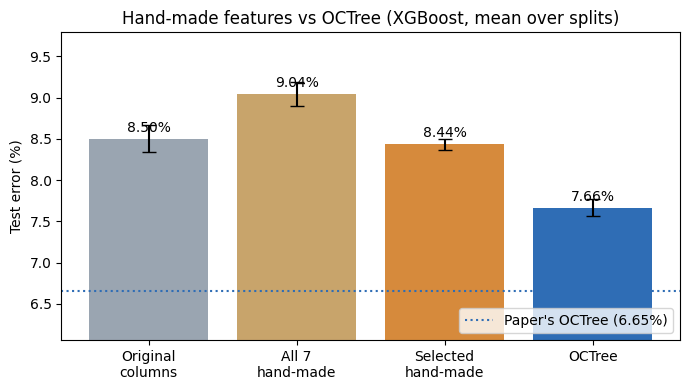

In [16]:
# Bar chart: mean test error (± standard deviation over splits)
labels = ["Original\ncolumns", "All 7\nhand-made", "Selected\nhand-made", "OCTree"]
means, stds = num.mean().values, num.std(ddof=0).values
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(labels, means, yerr=stds, capsize=5, color=["#9aa5b1", "#c8a46b", "#d68a3c", "#2f6db5"])
for b, m in zip(bars, means):
    if not np.isnan(m):
        ax.text(b.get_x() + b.get_width() / 2, m + 0.05, f"{m:.2f}%", ha="center", va="bottom")
ax.axhline(oc.PAPER["octree"], color="#2f6db5", linestyle=":", label=f"Paper's OCTree ({oc.PAPER['octree']}%)")
lo = np.nanmin(means - stds)
ax.set_ylim(max(0, lo - 1.5), np.nanmax(means + stds) + 0.6)
ax.set_ylabel("Test error (%)")
ax.set_title("Hand-made features vs OCTree (XGBoost, mean over splits)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [17]:
# Which hand-made features helped? Validation accuracy of each candidate as x9 (split 0), against the original columns.
man0 = oc.load_run(RUN_MANUAL, CFG["seeds"][0])
cand = pd.DataFrame([{"feature": t["name"], "val accuracy %": round(t["val"] * 100, 2),
                      "test accuracy %": round(t["test"] * 100, 2)} for t in man0["rounds"][0]["tried"]])
cand["vs original (val)"] = (cand["val accuracy %"] - round(man0["baseline"]["val"] * 100, 2)).round(2)
display(cand.sort_values("val accuracy %", ascending=False))

,feature,val accuracy %,test accuracy %,vs original (val)
1,demand_gap,91.25,91.24,-0.10
0,price_gap,91.23,91.53,-0.12
6,transfer_x_price_gap,91.06,91.29,-0.29
5,peak_hours,91.03,91.50,-0.32
4,period_cos,90.96,91.24,-0.39
3,period_sin,90.90,91.22,-0.45
2,price_x_demand,90.53,91.14,-0.82


### 7.2 Does training-set size change the value of generated features? (Data size experiment)

**Question.** A decision tree splits on one column at a time, so it needs many examples to learn a
relationship between two columns, such as a product or a difference. A generated column hands that
relationship over directly. We therefore expect generated features to matter **more** when training data is
scarce, and less as the training set grows.

**Design.** We train XGBoost on 10%, 25%, 50% and 100% of the training rows (random, nested subsets with a
fixed seed), each time with three inputs: the original columns, the original columns plus the selected
hand-made features (7.1), and the original columns plus OCTree's features (Section 5). Validation and test
sets are always the full ones, so every result is measured on exactly the same rows. XGBoost keeps the
authors' tuned settings at every size.

**Limitation.** OCTree's features were found using the full training set. This experiment therefore asks
whether a *given* feature is more useful with less data, not whether OCTree would *find* as good a feature
from less data (which would need a new set of LLM calls for each size).

In [18]:
FRACTIONS = (0.1, 0.25, 0.5, 1.0)
size_rows = []
for seed in CFG["seeds"]:
    octr, man = oc.load_run(RUN_OCTREE, seed), oc.load_run(RUN_MANUAL, seed)
    assert octr and octr.get("final") and man, f"Run Section 5 and 7.1 for split {seed} first."
    sets = {"original": [], "hand-made": man["final"]["rules"], "OCTree": octr["final"]["rules"]}
    size_rows += oc.run_data_size(seed, sets, RUN_DATA_SIZE, fractions=FRACTIONS,
                                  n_estimators=CFG["n_estimators"])
size = pd.DataFrame(size_rows)

table = size.pivot_table(index=["fraction", "train_rows"], columns="features", values="test_error", aggfunc="mean")
table = table[["original", "hand-made", "OCTree"]] if set(["hand-made", "OCTree"]) <= set(table.columns) else table
gain = table.drop(columns="original").rsub(table["original"], axis=0).add_prefix("gain from ")
display(pd.concat([table.round(2), gain.round(2)], axis=1).reset_index())
print("Values are mean test error (%) over splits; 'gain' = original error minus error with the features "
      "(positive = the features help).")

features,fraction,train_rows,original,hand-made,OCTree,gain from hand-made,gain from OCTree
0,0.10,2308,17.21,17.19,17.10,0.02,0.11
1,0.25,5771,13.67,13.68,13.20,-0.01,0.46
2,0.50,11542,11.13,11.02,10.64,0.11,0.49
3,1.00,23084,8.50,8.43,7.66,0.07,0.84


Values are mean test error (%) over splits; 'gain' = original error minus error with the features (positive = the features help).


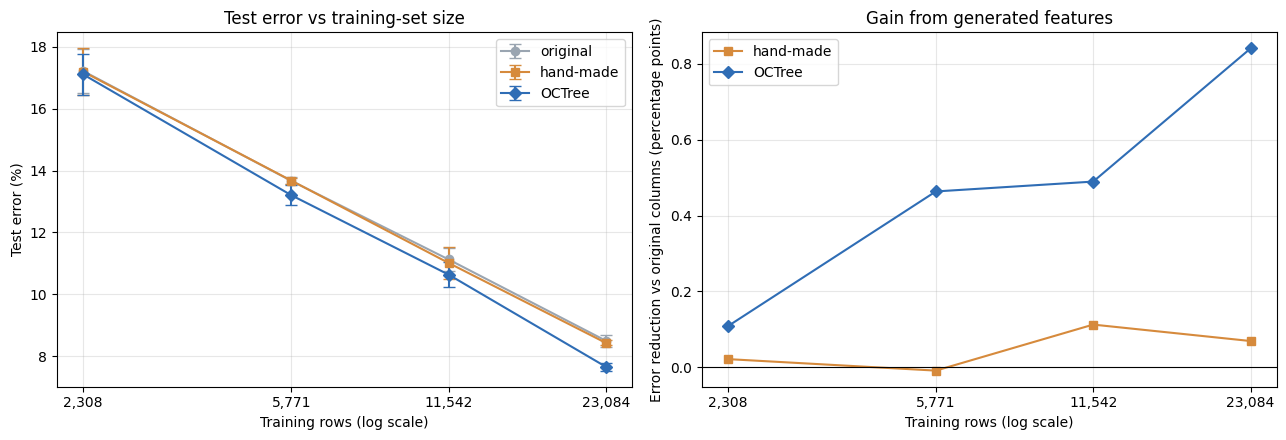

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
style = {"original": ("#9aa5b1", "o"), "hand-made": ("#d68a3c", "s"), "OCTree": ("#2f6db5", "D")}
agg = size.groupby(["fraction", "features"])["test_error"].agg(["mean", "std"]).reset_index()
rows_at = size.groupby("fraction")["train_rows"].mean()
for name, (color, marker) in style.items():
    d = agg[agg["features"] == name]
    if len(d):
        axes[0].errorbar(rows_at[d["fraction"]].values, d["mean"], yerr=d["std"].fillna(0), color=color,
                         marker=marker, capsize=4, label=name)
for name in ("hand-made", "OCTree"):
    if name in table.columns:
        axes[1].plot(table.index.get_level_values("train_rows"), table["original"] - table[name],
                     color=style[name][0], marker=style[name][1], label=name)
axes[0].set_title("Test error vs training-set size")
axes[0].set_ylabel("Test error (%)")
axes[1].set_title("Gain from generated features")
axes[1].set_ylabel("Error reduction vs original columns (percentage points)")
axes[1].axhline(0, color="black", linewidth=0.8)
for ax in axes:
    ax.set_xscale("log")
    ax.set_xticks(rows_at.values)
    ax.set_xticklabels([f"{int(v):,}" for v in rows_at.values])
    ax.minorticks_off()
    ax.set_xlabel("Training rows (log scale)")
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

**Reading the results.** If the right-hand curve for OCTree slopes downward (larger gains at small sizes), the
hypothesis holds: generated features substitute for data. If it is flat or rises, the features carry
information that XGBoost cannot learn from the original columns even with all the data. Compare the gains
with the spread between splits (error bars on the left) before calling a difference real.

## 8. Final model for deployment

We train the final XGBoost model on split 0 with the generated features OCTree kept, and save:

* `model/xgb_model.json`: the trained model;
* `model/pipeline.json`: how to turn eight raw inputs into the model's input (scaling values and the
  generated-feature rules), plus a few test examples.

`app.py` (Streamlit) and `predict.py` load these two files.

In [20]:
run0 = oc.load_run(RUN_OCTREE, CFG["seeds"][0])
final_rules = run0["final"]["rules"]
pipe = oc.train_final_model(CFG["seeds"][0], final_rules, model_dir="model", n_estimators=CFG["n_estimators"],
                            extra={"run": RUN_OCTREE, "proposer": run0["config"]["proposer"]})
print("Saved model/  |  generated features:", final_rules or "none",
      f"|  test error {pipe['metrics']['test_error_percent']:.2f}%")

# Inference check: Input -> Preprocessing -> Trained model -> Prediction -> Output
pipe, clf = oc.load_pipeline("model")
example = pipe["examples"][0]
labels, p_up = oc.predict(pipe, clf, [example["values"]])
print("\nInput     :", dict(zip(pipe["raw_columns"], example["values"])))
print(f"Prediction: {labels[0]}  (probability of UP = {p_up[0]:.3f})   true label: {example['true_label']}")

Saved model/  |  generated features: ['x9 = [np.where(x4 > 0.07, x1 * x3 * x4 + np.sin(x6 * x8) * (1 - x2), np.cos(x5 * x7) + x1 * x2 * (1 - x4))]', 'x10 = [np.where(x4 > 0.08, x3 * x9 * (np.abs(x1 - x5) + np.sin(x2 * x6) * np.exp(-x4)), x1 * x4 * np.cos(x3) + x7 * x8 * np.sin(x9) + np.sin(x1 * x2) * np.cos(x4))]'] |  test error 7.76%

Input     : {'date': 0.89381, 'day': 3.0, 'period': 0.06383, 'nswprice': 0.053381, 'nswdemand': 0.463106, 'vicprice': 0.003556, 'vicdemand': 0.481875, 'transfer': 0.528947}
Prediction: DOWN  (probability of UP = 0.001)   true label: DOWN


### 8.1 Metrics of the deployed model

The saved model is scored exactly as the app uses it: raw test values → preprocessing (scaling and generated
features from `pipeline.json`) → model. The test error must equal the one printed above. UP is the positive class.

In [21]:
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score
pipe, clf = oc.load_pipeline("model")
split = oc.load_split(pipe["seed"])
raw = split["xtest"] * (split["raw_max"] - split["raw_min"]) + split["raw_min"]    # back to the dataset's own scale
labels, p_up = oc.predict(pipe, clf, raw)
y_pred = (pd.Series(labels) == "UP").astype(int).to_numpy()
y = split["ytest"].astype(int)
print(f"test rows {len(y)} | accuracy {accuracy_score(y, y_pred) * 100:.2f}% | test error {100 - accuracy_score(y, y_pred) * 100:.2f}%")
print(f"UP class: precision {precision_score(y, y_pred) * 100:.2f}% | recall {recall_score(y, y_pred) * 100:.2f}% | F1 {f1_score(y, y_pred) * 100:.2f}%")
print("confusion matrix (rows = true DOWN, UP; columns = predicted DOWN, UP):")
print(confusion_matrix(y, y_pred))

test rows 7695 | accuracy 92.24% | test error 7.76%
UP class: precision 91.93% | recall 92.53% | F1 92.23%
confusion matrix (rows = true DOWN, UP; columns = predicted DOWN, UP):
[[3556  311]
 [ 286 3542]]


**Start the web app** from the project folder:

```
streamlit run app.py
```

On Colab, download the `model/` folder (or the whole project) and run the app on your own computer.